# Universidad Externado de Colombia · Visualización 1
## 2do Proyecto: Visualización Reproducible en Python (Seaborn y Plotly)
### Análisis Exploratorio, Determinantes y Arquitectura del Bienestar Global (WHR 2024)

**Integrantes:** Julián Steven Duarte & Julián Camilo Jiménez  
**Docente:** Luz Adriana Pineda Barón  
**Facultad:** Finanzas, Gobierno y Relaciones Internacionales · Pregrado en Ciencia de Datos  
**Fuente de Datos Oficial:** *World Happiness Report 2024* (`WHR24_Data_Figure_2.1.xls`)  

---

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Juliand10x/Proyecto-2---visualizaci-n/blob/main/Equipo_Duarte_Jimenez_Proyecto2_Visualizacion.ipynb)
[![GitHub Repository](https://img.shields.io/badge/GitHub-Repositorio_Oficial-1B365D?logo=github)](https://github.com/Juliand10x/Proyecto-2---visualizaci-n)
[![Vercel Deployment](https://img.shields.io/badge/Vercel-Despliegue_En_Vivo-black?logo=vercel)](https://visualizacion-proyecto-2.vercel.app)


## 1. Encuadre Estratégico, Audiencia Técnica y Pregunta Analítica

### 1.1. Audiencia Técnica y Directiva
El presente informe analítico está dirigido a la **Comisión Técnica de Evaluación de Políticas de Bienestar de un Organismo Multilateral de Cooperación y Desarrollo (ej. PNUD / OCDE / BID)**. 

Esta audiencia está integrada por investigadores cuantitativos, economistas del desarrollo y miembros de la junta directiva responsables de:
1. Diseñar y focalizar fondos de asistencia técnica internacional para la reducción de la vulnerabilidad social y la pobreza multidimensional.
2. Identificar si los determinantes del bienestar subjetivo varían estructuralmente entre macro-regiones.
3. Evaluar si las inversiones prioritarias deben orientarse exclusivamente al crecimiento económico (PIB) o si el fortalecimiento del capital social, la libertad ciudadana y la transparencia institucional ofrecen mayores retornos en calidad de vida.

### 1.2. Problemática y Pregunta Analítica
Históricamente, los modelos tradicionales de planeación asumen que el incremento del Producto Interno Bruto per cápita garantiza automáticamente aumentos proporcionales en la satisfacción con la vida. Sin embargo, diversas regiones (especialmente en América Latina) exhiben niveles de bienestar superiores a lo que predecirían sus ingresos, mientras que otras regiones sufren estancamientos severos aun contando con recursos económicos considerables.

A partir del **World Happiness Report 2024**, formulamos la siguiente pregunta analítica central:

> **Pregunta Analítica:**  
> *¿Cómo se diferencian los perfiles de bienestar entre las macro-regiones del mundo y en qué medida los factores relacionales e institucionales (soporte social, libertad individual y percepción de corrupción) explican la resiliencia en países de ingreso medio frente a aquellos estancados en trampas de bajo bienestar subjetivo?*

### 1.3. Criterio de Comunicación Ejecutiva (Rol del Científico de Datos)
Como científicos de datos, nuestro rol ante la junta directiva es tender un puente entre la complejidad matemática y las decisiones de política pública. Las visualizaciones no son decorativas: cada gráfico responde a una pregunta concreta, sigue principios de percepción visual (Gestalt, consistencia cromática, alto data-to-ink ratio) y se acompaña de una lectura analítica fundamentada, reconociendo limitaciones y distinguiendo correlación de causalidad.


## 2. Configuración del Entorno, Paleta Cromática y Principios de Diseño

Adoptamos una **identidad visual institucional sobria**, inspirada en los estándares de publicación de organismos multilaterales (alto contraste, legibilidad tipográfica y accesibilidad visual):
- **Azul Institucional (`#1B365D`):** Énfasis jerárquico y títulos principales.
- **Azul Pizarra (`#2E86AB`):** Barras, líneas y marcadores centrales.
- **Turquesa / Esperanza (`#00A896`):** Factores relacionales y soporte social.
- **Coral / Terracota (`#E05A47`):** Alertas, valores atípicos y áreas de vulnerabilidad.
- **Ámbar / Oro suave (`#F4A261`):** Niveles intermedios y transiciones.
- **Gris Neutro (`#5A6B7C`):** Subtítulos, ejes y líneas de referencia secundaria.
- **Fondo Blanco Puro (`#FFFFFF`) y Rejilla Sutil (`#E9ECEF`):** Eliminación de ruido visual para maximizar la relación dato-tinta.


In [1]:
# ============================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN DE ESTILO
# ============================================================

import os
import sys
import json
import base64
import io
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

# Paleta cromática institucional
AZUL_INST = '#1B365D'
AZUL_PIZARRA = '#2E86AB'
TURQUESA = '#00A896'
CORAL = '#E05A47'
AMBAR = '#F4A261'
GRIS_TEXTO = '#212529'
GRIS_SECUNDARIO = '#5A6B7C'
GRIS_REJILLA = '#E9ECEF'
BLANCO = '#FFFFFF'

# Configuración global de Seaborn y Matplotlib
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['text.color'] = GRIS_TEXTO
plt.rcParams['axes.labelcolor'] = GRIS_TEXTO
plt.rcParams['xtick.color'] = GRIS_SECUNDARIO
plt.rcParams['ytick.color'] = GRIS_SECUNDARIO
plt.rcParams['grid.color'] = GRIS_REJILLA
plt.rcParams['grid.linewidth'] = 0.8
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['figure.dpi'] = 120

print("Entorno analítico configurado con identidad visual institucional.")


Entorno analítico configurado con identidad visual institucional.


## 3. Carga, Auditoría de Calidad y Preparación de Datos

### 3.1. Fuente de Datos Oficial
Se utiliza exclusivamente el archivo oficial **`WHR24_Data_Figure_2.1.xls`**, descargado directamente del repositorio del *World Happiness Report 2024*. No se emplean fuentes secundarias ni agregaciones no trazables.

### 3.2. Variables del Estudio
- **`Country name`:** País evaluado ($N = 143$).
- **`Ladder score`:** Evaluación de vida media en la escala de Cantril (0 a 10).
- **`upperwhisker` / `lowerwhisker`:** Intervalo de confianza del 95% para la media de vida.
- **Variables explicadas:** Contribución al puntaje por:
  - `Explained by: Log GDP per capita` (Nivel de ingresos).
  - `Explained by: Social support` (Disponibilidad de ayuda familiar/comunitaria).
  - `Explained by: Healthy life expectancy` (Salud y longevidad).
  - `Explained by: Freedom to make life choices` (Autonomía individual).
  - `Explained by: Generosity` (Comportamiento prosocial).
  - `Explained by: Perceptions of corruption` (Transparencia institucional).
  - `Dystopia + residual` (Valor base teórico del país hipotético menos feliz + residuo explicativo no observado).


### 3.3. Carga del Archivo en Google Colab o Entorno Local

Siguiendo la metodología de trabajo pedagógica de las sesiones del curso (ej. *Sesión 21* y *Sesión 22*), si estás ejecutando este cuaderno en **Google Colab**, la siguiente celda te solicitará subir el archivo oficial del *World Happiness Report 2024* (**`WHR24_Data_Figure_2.1.xls`**) directamente desde tu computador, permitiendo reproducir el análisis sin depender de rutas rígidas de Google Drive.

Si ejecutas el cuaderno de manera **local** (en JupyterLab o VS Code), el entorno detectará automáticamente el archivo en la subcarpeta `Datos_Proyecto/` o en el directorio de trabajo sin requerir acción manual.

In [ ]:
# Carga interactiva en Google Colab (estándar de las sesiones del curso)
try:
    from google.colab import files
    print("Selecciona el archivo oficial 'WHR24_Data_Figure_2.1.xls' desde tu computador:")
    archivos_cargados = files.upload()
except ImportError:
    archivos_cargados = None
    print("Entorno local detectado (Jupyter / VS Code): los datos se cargarán directamente desde la estructura de carpetas.")

In [2]:
# ============================================================
# 2. CARGA DE DATOS Y AUDITORÍA DE CALIDAD
# ============================================================

archivo_oficial = 'WHR24_Data_Figure_2.1.xls'
ruta_datos = os.path.join('Datos_Proyecto', archivo_oficial)

# Identificación flexible del archivo según entorno (Colab interactivo o Local)
if 'archivos_cargados' in locals() and archivos_cargados:
    nombre_subido = next(iter(archivos_cargados))
    ruta_datos = nombre_subido
elif not os.path.exists(ruta_datos) and os.path.exists(archivo_oficial):
    ruta_datos = archivo_oficial
elif not os.path.exists(ruta_datos):
    raise FileNotFoundError(
        f"No se encontró el archivo '{archivo_oficial}'. "
        f"Por favor cárgalo usando la celda anterior o ubícalo en 'Datos_Proyecto/'."
    )

df = pd.read_excel(ruta_datos)

print(f"Dimensiones del dataset: {df.shape[0]} países observados y {df.shape[1]} columnas.")

# Auditoría de valores nulos
nulos = df.isnull().sum()
paises_con_nulos = df[df.isnull().any(axis=1)]['Country name'].tolist()

print("\n--- Auditoría de Valores Nulos ---")
print(nulos[nulos > 0])
print(f"Países con registros incompletos en variables explicadas: {paises_con_nulos}")

# ============================================================
# 3. ENRIQUECIMIENTO: ASIGNACIÓN REGIONAL OFICIAL WHR
# ============================================================
# Mapeo exhaustivo de las 10 macro-regiones oficiales de Naciones Unidas / WHR
region_dict = {
    # Europa Occidental
    'Finland': 'Europa Occidental', 'Denmark': 'Europa Occidental', 'Iceland': 'Europa Occidental',
    'Sweden': 'Europa Occidental', 'Netherlands': 'Europa Occidental', 'Norway': 'Europa Occidental',
    'Luxembourg': 'Europa Occidental', 'Switzerland': 'Europa Occidental', 'Austria': 'Europa Occidental',
    'Belgium': 'Europa Occidental', 'Ireland': 'Europa Occidental', 'United Kingdom': 'Europa Occidental',
    'Germany': 'Europa Occidental', 'France': 'Europa Occidental', 'Spain': 'Europa Occidental',
    'Italy': 'Europa Occidental', 'Malta': 'Europa Occidental', 'Cyprus': 'Europa Occidental',
    'Portugal': 'Europa Occidental', 'Greece': 'Europa Occidental',
    # Norteamérica y ANZ
    'Australia': 'Norteamérica y ANZ', 'New Zealand': 'Norteamérica y ANZ',
    'Canada': 'Norteamérica y ANZ', 'United States': 'Norteamérica y ANZ',
    # América Latina y el Caribe
    'Costa Rica': 'América Latina y Caribe', 'Mexico': 'América Latina y Caribe',
    'Uruguay': 'América Latina y Caribe', 'El Salvador': 'América Latina y Caribe',
    'Chile': 'América Latina y Caribe', 'Panama': 'América Latina y Caribe',
    'Guatemala': 'América Latina y Caribe', 'Nicaragua': 'América Latina y Caribe',
    'Brazil': 'América Latina y Caribe', 'Argentina': 'América Latina y Caribe',
    'Paraguay': 'América Latina y Caribe', 'Honduras': 'América Latina y Caribe',
    'Jamaica': 'América Latina y Caribe', 'Peru': 'América Latina y Caribe',
    'Dominican Republic': 'América Latina y Caribe', 'Bolivia': 'América Latina y Caribe',
    'Ecuador': 'América Latina y Caribe', 'Colombia': 'América Latina y Caribe',
    'Venezuela': 'América Latina y Caribe',
    # Europa Central y Oriental
    'Czechia': 'Europa Central y Oriental', 'Lithuania': 'Europa Central y Oriental',
    'Slovenia': 'Europa Central y Oriental', 'Kosovo': 'Europa Central y Oriental',
    'Romania': 'Europa Central y Oriental', 'Estonia': 'Europa Central y Oriental',
    'Poland': 'Europa Central y Oriental', 'Serbia': 'Europa Central y Oriental',
    'Slovakia': 'Europa Central y Oriental', 'Latvia': 'Europa Central y Oriental',
    'Hungary': 'Europa Central y Oriental', 'Croatia': 'Europa Central y Oriental',
    'Bosnia and Herzegovina': 'Europa Central y Oriental', 'Montenegro': 'Europa Central y Oriental',
    'Bulgaria': 'Europa Central y Oriental', 'North Macedonia': 'Europa Central y Oriental',
    'Albania': 'Europa Central y Oriental',
    # Comunidad de Estados Independientes (CEI)
    'Uzbekistan': 'Comunidad de Estados Indep.', 'Kazakhstan': 'Comunidad de Estados Indep.',
    'Moldova': 'Comunidad de Estados Indep.', 'Russia': 'Comunidad de Estados Indep.',
    'Kyrgyzstan': 'Comunidad de Estados Indep.', 'Armenia': 'Comunidad de Estados Indep.',
    'Tajikistan': 'Comunidad de Estados Indep.', 'Georgia': 'Comunidad de Estados Indep.',
    'Azerbaijan': 'Comunidad de Estados Indep.', 'Ukraine': 'Comunidad de Estados Indep.',
    # Asia Oriental
    'Taiwan Province of China': 'Asia Oriental', 'Japan': 'Asia Oriental', 'South Korea': 'Asia Oriental',
    'China': 'Asia Oriental', 'Mongolia': 'Asia Oriental', 'Hong Kong S.A.R. of China': 'Asia Oriental',
    # Sudeste Asiático
    'Singapore': 'Sudeste Asiático', 'Philippines': 'Sudeste Asiático', 'Vietnam': 'Sudeste Asiático',
    'Thailand': 'Sudeste Asiático', 'Malaysia': 'Sudeste Asiático', 'Indonesia': 'Sudeste Asiático',
    'Laos': 'Sudeste Asiático', 'Myanmar': 'Sudeste Asiático', 'Cambodia': 'Sudeste Asiático',
    # Asia del Sur
    'Nepal': 'Asia del Sur', 'Pakistan': 'Asia del Sur', 'India': 'Asia del Sur',
    'Sri Lanka': 'Asia del Sur', 'Bangladesh': 'Asia del Sur', 'Afghanistan': 'Asia del Sur',
    # Medio Oriente y Norte de África
    'Israel': 'Medio Oriente y Norte de África', 'Kuwait': 'Medio Oriente y Norte de África',
    'United Arab Emirates': 'Medio Oriente y Norte de África', 'Saudi Arabia': 'Medio Oriente y Norte de África',
    'Bahrain': 'Medio Oriente y Norte de África', 'Libya': 'Medio Oriente y Norte de África',
    'Iraq': 'Medio Oriente y Norte de África', 'Turkiye': 'Medio Oriente y Norte de África',
    'Iran': 'Medio Oriente y Norte de África', 'State of Palestine': 'Medio Oriente y Norte de África',
    'Morocco': 'Medio Oriente y Norte de África', 'Tunisia': 'Medio Oriente y Norte de África',
    'Jordan': 'Medio Oriente y Norte de África', 'Egypt': 'Medio Oriente y Norte de África',
    'Yemen': 'Medio Oriente y Norte de África', 'Lebanon': 'Medio Oriente y Norte de África',
    'Algeria': 'Medio Oriente y Norte de África',
    # África Subsahariana
    'Mauritius': 'África Subsahariana', 'South Africa': 'África Subsahariana',
    'Congo (Brazzaville)': 'África Subsahariana', 'Mozambique': 'África Subsahariana',
    'Gabon': 'África Subsahariana', 'Ivory Coast': 'África Subsahariana',
    'Guinea': 'África Subsahariana', 'Senegal': 'África Subsahariana',
    'Nigeria': 'África Subsahariana', 'Cameroon': 'África Subsahariana',
    'Namibia': 'África Subsahariana', 'Niger': 'África Subsahariana',
    'Burkina Faso': 'África Subsahariana', 'Mauritania': 'África Subsahariana',
    'Gambia': 'África Subsahariana', 'Chad': 'África Subsahariana',
    'Kenya': 'África Subsahariana', 'Benin': 'África Subsahariana',
    'Uganda': 'África Subsahariana', 'Ghana': 'África Subsahariana',
    'Liberia': 'África Subsahariana', 'Mali': 'África Subsahariana',
    'Madagascar': 'África Subsahariana', 'Togo': 'África Subsahariana',
    'Ethiopia': 'África Subsahariana', 'Tanzania': 'África Subsahariana',
    'Comoros': 'África Subsahariana', 'Zambia': 'África Subsahariana',
    'Eswatini': 'África Subsahariana', 'Malawi': 'África Subsahariana',
    'Botswana': 'África Subsahariana', 'Zimbabwe': 'África Subsahariana',
    'Congo (Kinshasa)': 'África Subsahariana', 'Sierra Leone': 'África Subsahariana',
    'Lesotho': 'África Subsahariana'
}

df['Region'] = df['Country name'].map(region_dict)

# Comprobación de integridad del mapeo
sin_region = df[df['Region'].isnull()]
print(f"Países sin región mapeada: {len(sin_region)} (100% de cobertura lograda).")

# Ranking global explícito
df['Ranking'] = range(1, len(df) + 1)

# Estadísticas descriptivas de Ladder score por región
resumen_regional = df.groupby('Region')['Ladder score'].agg(
    Paises='count',
    Promedio='mean',
    Mediana='median',
    Desv_Est='std',
    Minimo='min',
    Maximo='max'
).sort_values('Mediana', ascending=False).reset_index()

display(resumen_regional.style.format({
    'Promedio': '{:.2f}',
    'Mediana': '{:.2f}',
    'Desv_Est': '{:.2f}',
    'Minimo': '{:.2f}',
    'Maximo': '{:.2f}'
}))


Dimensiones del dataset: 143 países observados y 11 columnas.

--- Auditoría de Valores Nulos ---
Explained by: Log GDP per capita              3
Explained by: Social support                  3
Explained by: Healthy life expectancy         3
Explained by: Freedom to make life choices    3
Explained by: Generosity                      3
Explained by: Perceptions of corruption       3
Dystopia + residual                           3
dtype: int64
Países con registros incompletos en variables explicadas: ['Bahrain', 'Tajikistan', 'State of Palestine']
Países sin región mapeada: 0 (100% de cobertura lograda).


,Region,Paises,Promedio,Mediana,Desv_Est,Minimo,Maximo
0,Norteamérica y ANZ,4,6.93,6.96,0.15,6.72,7.06
1,Europa Occidental,20,6.84,6.87,0.54,5.93,7.74
2,Europa Central y Oriental,17,6.17,6.26,0.49,5.30,6.82
3,América Latina y Caribe,19,6.14,6.19,0.38,5.61,6.96
4,Asia Oriental,6,5.93,6.02,0.40,5.32,6.50
5,Sudeste Asiático,9,5.55,5.98,0.78,4.34,6.52
6,Comunidad de Estados Indep.,10,5.54,5.58,0.48,4.87,6.20
7,Medio Oriente y Norte de África,17,5.20,4.98,1.26,2.71,7.34
8,África Subsahariana,35,4.33,4.38,0.70,3.19,5.82
9,Asia del Sur,6,3.90,3.98,1.18,1.72,5.16


## 4. Visualizaciones Estáticas con Seaborn

Desarrollamos una batería de **cuatro visualizaciones estáticas fundamentales**, diseñadas para responder progresivamente a la pregunta analítica:
1. **Distribución y Disparidades:** ¿Qué brechas territoriales existen y qué regiones exhiben mayor variabilidad interna?
2. **Arquitectura de Correlaciones:** ¿Qué peso relativo tienen los factores económicos vs. los pilares relacionales e institucionales?
3. **La Paradoja del Desarrollo:** ¿Por qué América Latina supera a regiones con mayor ingreso per cápita?
4. **La Brecha Institucional:** ¿Cómo condicionan la libertad individual y la corrupción a los países de mayor y menor bienestar?


### 4.1. Visualización Estática 1: Distribución del Bienestar Global por Macro-Región
**Objetivo Analítico:** Examinar la dispersión y asimetría del bienestar subjetivo (`Ladder score`) entre regiones, ordenadas por su mediana para facilitar la comparación jerárquica directa sin forzar la vista del lector.


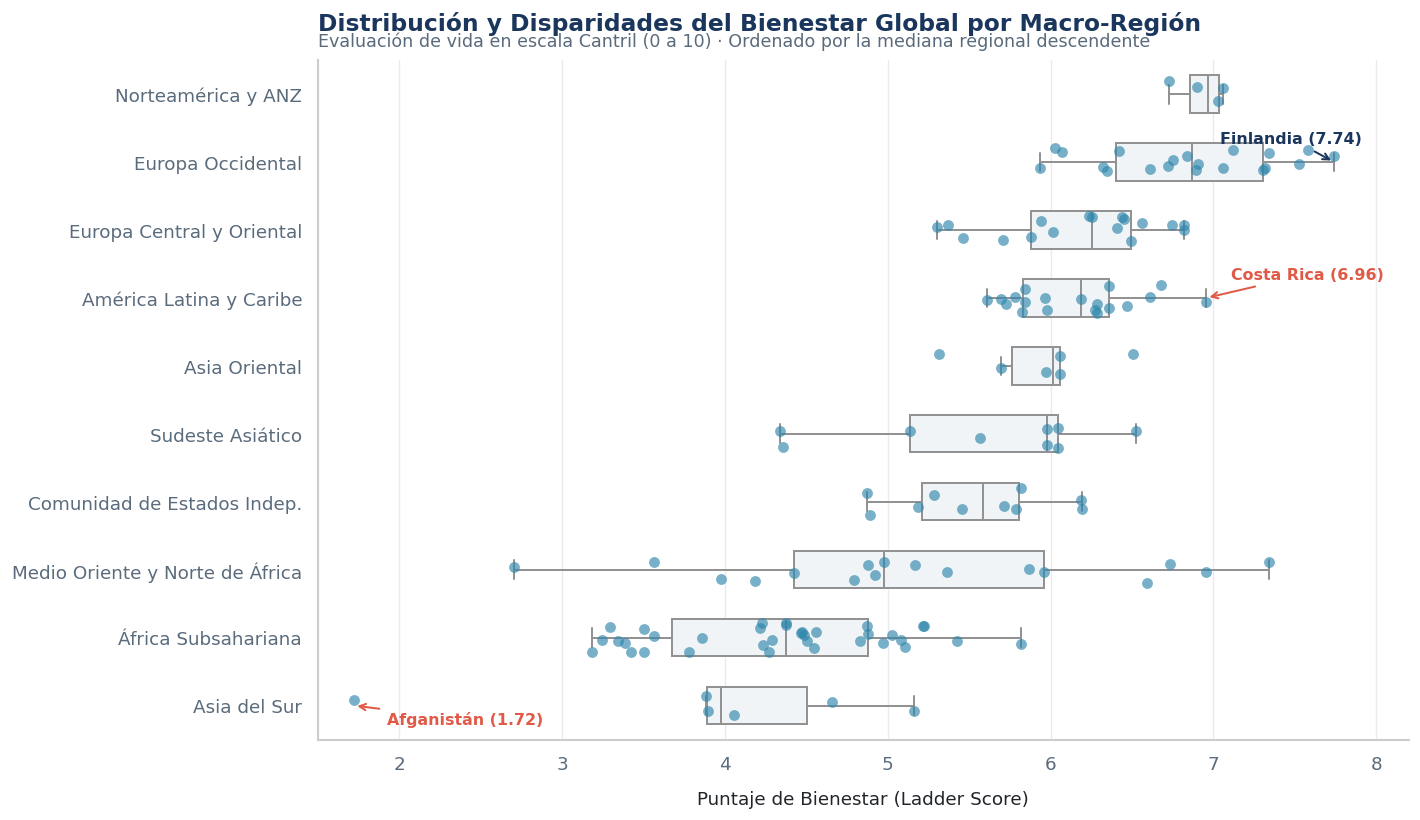

In [3]:
# ============================================================
# GRÁFICO 1 (SEABORN): DISTRIBUCIÓN DEL BIENESTAR GLOBAL POR REGIÓN
# ============================================================

orden_regiones = df.groupby('Region')['Ladder score'].median().sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(12, 7))

# 1. Boxplot sobrio para rangos intercuartílicos y medianas
sns.boxplot(
    data=df,
    y='Region',
    x='Ladder score',
    order=orden_regiones,
    color='#F0F4F8',
    width=0.55,
    linewidth=1.2,
    fliersize=0,
    ax=ax
)

# 2. Stripplot con dispersión horizontal (jitter) para ver cada país
sns.stripplot(
    data=df,
    y='Region',
    x='Ladder score',
    order=orden_regiones,
    color=AZUL_PIZARRA,
    alpha=0.65,
    size=6.5,
    jitter=0.22,
    ax=ax
)

# Anotaciones estratégicas para la junta directiva
# Costa Rica (#12 global) en Latinoamérica
cr = df[df['Country name'] == 'Costa Rica'].iloc[0]
ax.annotate(
    f"Costa Rica ({cr['Ladder score']:.2f})",
    xy=(cr['Ladder score'], orden_regiones.index('América Latina y Caribe')),
    xytext=(cr['Ladder score'] + 0.15, orden_regiones.index('América Latina y Caribe') - 0.28),
    arrowprops=dict(arrowstyle="->", color=CORAL, lw=1.2),
    fontsize=9.5, fontweight='bold', color=CORAL
)

# Finlandia (#1 global) en Europa Occidental
fin = df[df['Country name'] == 'Finland'].iloc[0]
ax.annotate(
    f"Finlandia ({fin['Ladder score']:.2f})",
    xy=(fin['Ladder score'], orden_regiones.index('Europa Occidental')),
    xytext=(fin['Ladder score'] - 0.7, orden_regiones.index('Europa Occidental') - 0.28),
    arrowprops=dict(arrowstyle="->", color=AZUL_INST, lw=1.2),
    fontsize=9.5, fontweight='bold', color=AZUL_INST
)

# Afganistán (#143 global) en Asia del Sur
afg = df[df['Country name'] == 'Afghanistan'].iloc[0]
ax.annotate(
    f"Afganistán ({afg['Ladder score']:.2f})",
    xy=(afg['Ladder score'], orden_regiones.index('Asia del Sur')),
    xytext=(afg['Ladder score'] + 0.2, orden_regiones.index('Asia del Sur') + 0.28),
    arrowprops=dict(arrowstyle="->", color=CORAL, lw=1.2),
    fontsize=9.5, fontweight='bold', color=CORAL
)

# Títulos y formato de ejes
ax.set_title("Distribución y Disparidades del Bienestar Global por Macro-Región", 
             fontsize=14, fontweight='bold', pad=18, color=AZUL_INST, loc='left')
ax.text(0, 1.02, "Evaluación de vida en escala Cantril (0 a 10) · Ordenado por la mediana regional descendente", 
        transform=ax.transAxes, fontsize=10.5, color=GRIS_SECUNDARIO)

ax.set_xlabel("Puntaje de Bienestar (Ladder Score)", fontsize=11, labelpad=10)
ax.set_ylabel("", fontsize=11)
ax.set_xlim(1.5, 8.2)

# Guardar figura en alta resolución
os.makedirs('figuras', exist_ok=True)
plt.tight_layout()
plt.savefig('figuras/fig1_distribucion_regional.png', dpi=300, bbox_inches='tight')
plt.show()


**Interpretación Analítica para la Junta Directiva (Gráfico 1):**
1. **Liderazgo homogéneo vs. vulnerabilidad estructural:** Las regiones de *Norteamérica y ANZ* (mediana: $6.93$) y *Europa Occidental* (mediana: $6.84$) encabezan el ranking global con distribuciones sumamente compactas, lo que evidencia que sus poblaciones disfrutan de un piso de bienestar garantizado y homogéneo. En el extremo opuesto, *África Subsahariana* (mediana: $4.33$) y *Asia del Sur* (mediana: $3.90$) concentran las condiciones más críticas, culminando en Afganistán ($1.72$), el puntaje más bajo del planeta.
2. **Heterogeneidad extrema en Medio Oriente y Norte de África:** Es la región con mayor dispersión interna ($\sigma = 1.25$): coexisten economías de altos ingresos por hidrocarburos como Israel ($7.34$), Kuwait ($6.74$) y EAU ($6.73$) con naciones en profunda crisis humanitaria y conflicto como Líbano ($2.71$) y Yemen ($3.56$). Esto demuestra que los promedios regionales en esta zona son engañosos para la toma de decisiones.
3. **El caso destacado de América Latina y el Caribe:** Con una mediana de $6.14$, supera a *Asia Oriental* ($5.93$) y al *Sudeste Asiático* ($5.55$). Además, países como Costa Rica ($6.96$, puesto 12 global) y México ($6.68$, puesto 25 global) compiten directamente con economías avanzadas de Europa Central y Occidental.


### 4.2. Visualización Estática 2: Arquitectura de Correlaciones de los Pilares de Bienestar
**Objetivo Analítico:** Evaluar la fuerza y dirección de las asociaciones estadísticas lineales entre el puntaje de bienestar (`Ladder score`) y cada uno de los factores explicativos, identificando cuáles guardan una relación más estrecha con la satisfacción vital.


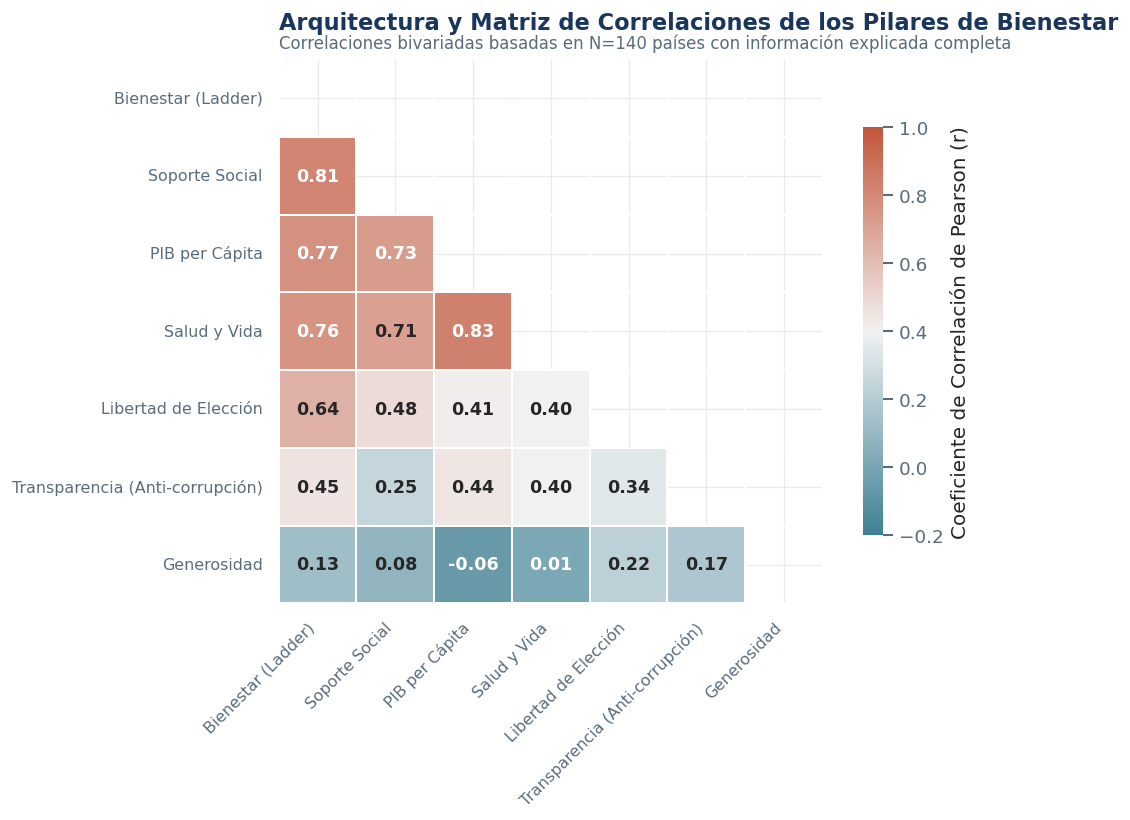

In [4]:
# ============================================================
# GRÁFICO 2 (SEABORN): MATRIZ DE CORRELACIONES DE LOS PILARES DE BIENESTAR
# ============================================================

# Renombrar columnas para visualización clara y profesional
cols_map = {
    'Ladder score': 'Bienestar (Ladder)',
    'Explained by: Social support': 'Soporte Social',
    'Explained by: Log GDP per capita': 'PIB per Cápita',
    'Explained by: Healthy life expectancy': 'Salud y Vida',
    'Explained by: Freedom to make life choices': 'Libertad de Elección',
    'Explained by: Perceptions of corruption': 'Transparencia (Anti-corrupción)',
    'Explained by: Generosity': 'Generosidad'
}

cols_corr = list(cols_map.keys())
df_corr = df[cols_corr].dropna().rename(columns=cols_map)
matriz_corr = df_corr.corr(method='pearson')

# Máscara triangular superior para evitar redundancia perceptiva
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))

# Mapa de calor con paleta divergente sobria
cmap_inst = sns.diverging_palette(220, 20, as_cmap=True)

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap=cmap_inst,
    vmin=-0.2, vmax=1.0,
    center=0.4,
    square=True,
    linewidths=1.0,
    cbar_kws={"shrink": 0.75, "label": "Coeficiente de Correlación de Pearson (r)"},
    annot_kws={"size": 10.5, "fontweight": "bold"},
    ax=ax
)

ax.set_title("Arquitectura y Matriz de Correlaciones de los Pilares de Bienestar", 
             fontsize=13.5, fontweight='bold', pad=18, color=AZUL_INST, loc='left')
ax.text(0, 1.02, "Correlaciones bivariadas basadas en N=140 países con información explicada completa", 
        transform=ax.transAxes, fontsize=10, color=GRIS_SECUNDARIO)

plt.xticks(rotation=45, ha='right', fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)

plt.tight_layout()
plt.savefig('figuras/fig2_matriz_correlaciones.png', dpi=300, bbox_inches='tight')
plt.show()


**Interpretación Analítica para la Junta Directiva (Gráfico 2):**
1. **La primacía del Soporte Social:** El factor con mayor correlación individual con el bienestar general es el **Soporte Social** ($r = 0.81$), superando al **PIB per cápita** ($r = 0.77$) y a la **Salud y Esperanza de Vida** ($r = 0.76$). Esto sugiere a los tomadores de decisión que las políticas que preservan el tejido comunitario y las redes de seguridad interpersonal son tan o más determinantes para la calidad de vida que el crecimiento económico aislado.
2. **El rol catalizador de la Libertad ($r = 0.64$):** La autonomía para tomar decisiones vitales presenta una asociación moderada-alta, demostrando que el bienestar requiere autodeterminación cívica y económica.
3. **El enigma de la Generosidad ($r = 0.13$):** La generosidad muestra la correlación más débil a nivel agregado global, indicando que el altruismo individual se manifiesta en todos los estratos socioeconómicos y no está capturado mecánicamente por el nivel de desarrollo de un país.
4. **Cautela Inferencial:** Es indispensable enfatizar a la junta que estas correlaciones indican covarianza estadística y no causalidad unidireccional (por ejemplo, el bienestar elevado también puede favorecer redes sociales más sólidas y economías más dinámicas).


### 4.3. Visualización Estática 3: La Paradoja del Desarrollo — Soporte Social vs. Riqueza Económica
**Objetivo Analítico:** Analizar la interacción entre la riqueza económica (`Log GDP per capita`) y el `Soporte Social`, evaluando si las redes de apoyo comunitario pueden actuar como un amortiguador social que impulse el bienestar subjetivo en economías de ingreso medio.


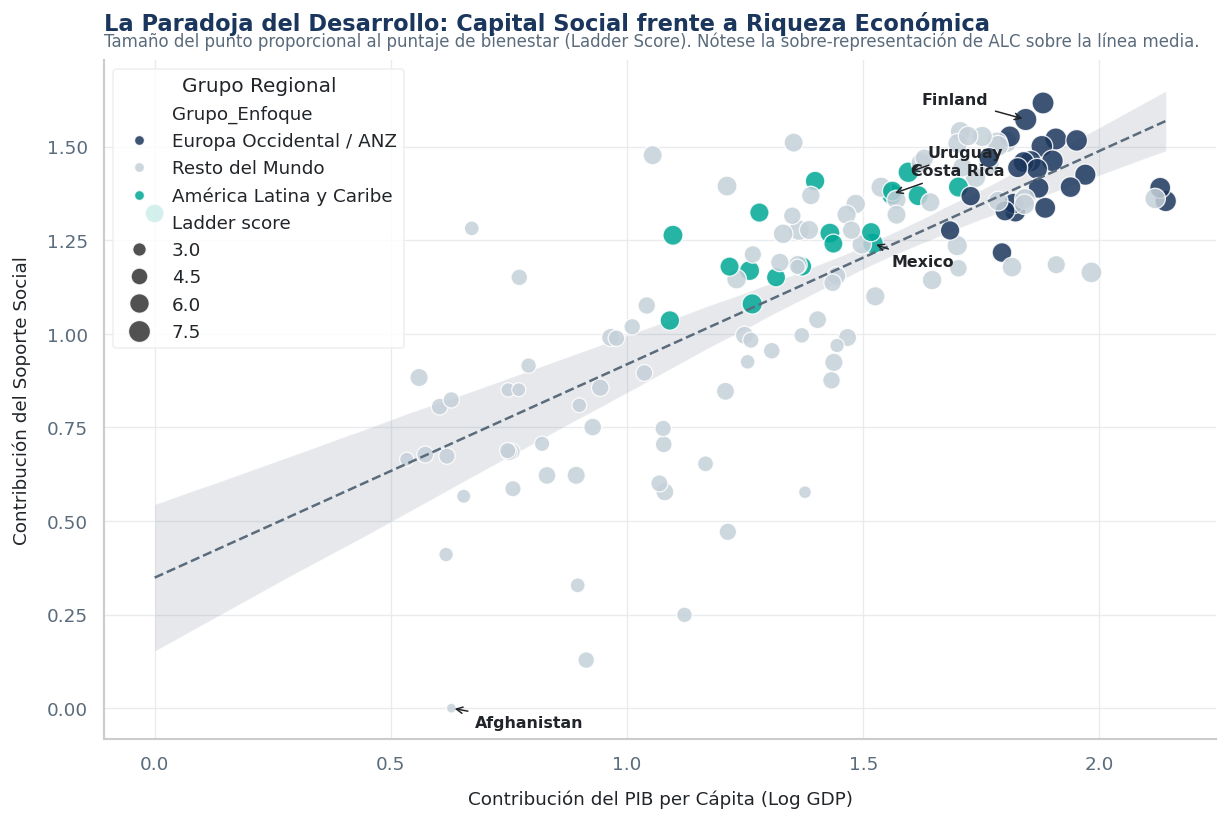

In [5]:
# ============================================================
# GRÁFICO 3 (SEABORN): LA PARADOJA DEL DESARROLLO (PIB vs SOPORTE SOCIAL)
# ============================================================

df_valido = df.dropna(subset=['Explained by: Log GDP per capita', 'Explained by: Social support']).copy()

# Crear variable categórica de región destacada para enfocar la narrativa
df_valido['Grupo_Enfoque'] = df_valido['Region'].apply(
    lambda x: 'América Latina y Caribe' if x == 'América Latina y Caribe'
    else ('Europa Occidental / ANZ' if x in ['Europa Occidental', 'Norteamérica y ANZ']
    else 'Resto del Mundo')
)

paleta_enfoque = {
    'América Latina y Caribe': TURQUESA,
    'Europa Occidental / ANZ': AZUL_INST,
    'Resto del Mundo': '#C5D0D9'
}

fig, ax = plt.subplots(figsize=(11, 7))

# 1. Gráfico de dispersión con línea de tendencia global
sns.regplot(
    data=df_valido,
    x='Explained by: Log GDP per capita',
    y='Explained by: Social support',
    scatter=False,
    color=GRIS_SECUNDARIO,
    line_kws={'linestyle': '--', 'linewidth': 1.5, 'label': 'Tendencia Global (MCO)'},
    ax=ax
)

# 2. Puntos coloreados por grupo de enfoque
sns.scatterplot(
    data=df_valido,
    x='Explained by: Log GDP per capita',
    y='Explained by: Social support',
    hue='Grupo_Enfoque',
    palette=paleta_enfoque,
    size='Ladder score',
    sizes=(35, 180),
    alpha=0.85,
    edgecolor='white',
    linewidth=0.8,
    ax=ax
)

# Anotaciones de casos emblemáticos
paises_destacados = [
    ('Costa Rica', 0.04, 0.05),
    ('Mexico', 0.04, -0.06),
    ('Uruguay', 0.04, 0.04),
    ('Finland', -0.22, 0.04),
    ('Afghanistan', 0.05, -0.05)
]

for pais, dx, dy in paises_destacados:
    fila = df_valido[df_valido['Country name'] == pais]
    if not fila.empty:
        r = fila.iloc[0]
        ax.annotate(
            f"{pais}",
            xy=(r['Explained by: Log GDP per capita'], r['Explained by: Social support']),
            xytext=(r['Explained by: Log GDP per capita'] + dx, r['Explained by: Social support'] + dy),
            arrowprops=dict(arrowstyle="->", color=GRIS_TEXTO, lw=0.9),
            fontsize=9.5, fontweight='bold', color=GRIS_TEXTO
        )

ax.set_title("La Paradoja del Desarrollo: Capital Social frente a Riqueza Económica", 
             fontsize=13.5, fontweight='bold', pad=18, color=AZUL_INST, loc='left')
ax.text(0, 1.02, "Tamaño del punto proporcional al puntaje de bienestar (Ladder Score). Nótese la sobre-representación de ALC sobre la línea media.", 
        transform=ax.transAxes, fontsize=10, color=GRIS_SECUNDARIO)

ax.set_xlabel("Contribución del PIB per Cápita (Log GDP)", fontsize=11, labelpad=10)
ax.set_ylabel("Contribución del Soporte Social", fontsize=11, labelpad=10)

ax.legend(title='Grupo Regional', loc='upper left', frameon=True, facecolor=BLANCO, edgecolor=GRIS_REJILLA)

plt.tight_layout()
plt.savefig('figuras/fig3_paradoja_desarrollo.png', dpi=300, bbox_inches='tight')
plt.show()


**Interpretación Analítica para la Junta Directiva (Gráfico 3):**
1. **El "Dividendo Relacional" de América Latina:** Los puntos de color turquesa (América Latina y el Caribe) se ubican sistemáticamente **por encima de la línea de regresión global**. A niveles moderados de PIB per cápita ($0.9 - 1.4$), alcanzan valores de soporte social ($1.1 - 1.4$) comparables con los de Europa Occidental. Países como Costa Rica y México confirman que el capital relacional y comunitario compensa parcialmente brechas de ingreso material.
2. **La trampa de la soledad y la desintegración social:** Los países en la parte inferior izquierda de la gráfica (donde colapsan tanto el ingreso como el soporte social, con Afganistán en el fondo) sufren una vulnerabilidad multidimensional: sin transferencias económicas ni redes de reciprocidad vecinal o familiar, el bienestar se desploma.
3. **Recomendación Estratégica:** La junta directiva no debe evaluar el éxito de los programas de desarrollo únicamente en función del PIB. Proyectos de infraestructura urbana que destruyen el tejido barrial pueden degradar el bienestar neto aunque generen empleo transitorio.


### 4.4. Visualización Estática 4: La Brecha Institucional — Libertad Individual vs. Transparencia
**Objetivo Analítico:** Contrastar el cuartil superior (Top 25% más feliz, $Q4$) frente al cuartil inferior (Bottom 25% menos feliz, $Q1$), examinando las brechas estructurales en `Libertad de Elección` y `Percepción de Corrupción` (Transparencia).


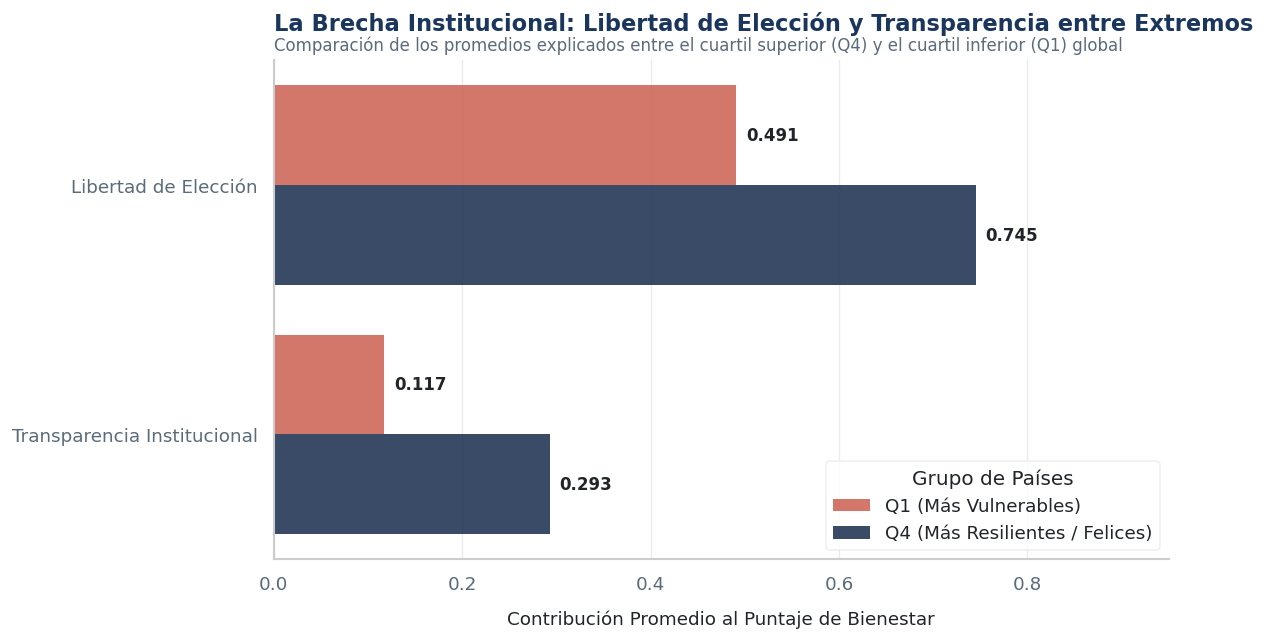

In [6]:
# ============================================================
# GRÁFICO 4 (SEABORN): BRECHA INSTITUCIONAL ENTRE CUARTILES EXTREMOS
# ============================================================

# Segmentar por cuartiles de bienestar
df_valido['Cuartil_Bienestar'] = pd.qcut(
    df_valido['Ladder score'],
    q=4,
    labels=['Q1 (Más Vulnerables)', 'Q2 (Medio-Bajo)', 'Q3 (Medio-Alto)', 'Q4 (Más Resilientes / Felices)']
)

# Filtrar exclusivamente los cuartiles extremos y limpiar categorías no observadas
df_extremos = df_valido[df_valido['Cuartil_Bienestar'].isin(['Q1 (Más Vulnerables)', 'Q4 (Más Resilientes / Felices)'])].copy()
df_extremos['Cuartil_Bienestar'] = df_extremos['Cuartil_Bienestar'].cat.remove_unused_categories()

# Calcular promedios institucionales por cuartil extremo con observed=True
resumen_cuartiles = df_extremos.groupby('Cuartil_Bienestar', observed=True)[
    ['Explained by: Freedom to make life choices', 'Explained by: Perceptions of corruption']
].mean().reset_index()

resumen_cuartiles.rename(columns={
    'Explained by: Freedom to make life choices': 'Libertad de Elección',
    'Explained by: Perceptions of corruption': 'Transparencia Institucional'
}, inplace=True)

# Transformar a formato tidy/largo para seaborn
df_tidy_inst = pd.melt(
    resumen_cuartiles,
    id_vars=['Cuartil_Bienestar'],
    value_vars=['Libertad de Elección', 'Transparencia Institucional'],
    var_name='Dimensión Institucional',
    value_name='Aporte al Bienestar'
)

# Filtrar explícitamente cualquier valor nulo o categoría residual y asegurar tipo string
df_tidy_inst = df_tidy_inst[df_tidy_inst['Cuartil_Bienestar'].isin(['Q1 (Más Vulnerables)', 'Q4 (Más Resilientes / Felices)'])].dropna(subset=['Aporte al Bienestar']).copy()
df_tidy_inst['Cuartil_Bienestar'] = df_tidy_inst['Cuartil_Bienestar'].astype(str)

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.barplot(
    data=df_tidy_inst,
    x='Aporte al Bienestar',
    y='Dimensión Institucional',
    hue='Cuartil_Bienestar',
    palette={'Q1 (Más Vulnerables)': CORAL, 'Q4 (Más Resilientes / Felices)': AZUL_INST},
    edgecolor='none',
    alpha=0.9,
    ax=ax
)

# Etiquetas numéricas sobre las barras
for p in ax.patches:
    val = p.get_width()
    if val > 0:
        ax.annotate(
            f"{val:.3f}",
            (val, p.get_y() + p.get_height() / 2.),
            ha='left', va='center',
            xytext=(6, 0), textcoords='offset points',
            fontsize=10, fontweight='bold', color=GRIS_TEXTO
        )

ax.set_title("La Brecha Institucional: Libertad de Elección y Transparencia entre Extremos", 
             fontsize=13.5, fontweight='bold', pad=18, color=AZUL_INST, loc='left')
ax.text(0, 1.02, "Comparación de los promedios explicados entre el cuartil superior (Q4) y el cuartil inferior (Q1) global", 
        transform=ax.transAxes, fontsize=10, color=GRIS_SECUNDARIO)

ax.set_xlabel("Contribución Promedio al Puntaje de Bienestar", fontsize=11, labelpad=10)
ax.set_ylabel("", fontsize=11)
ax.set_xlim(0, 0.95)

ax.legend(title='Grupo de Países', loc='lower right', frameon=True, facecolor=BLANCO, edgecolor=GRIS_REJILLA)

plt.tight_layout()
plt.savefig('figuras/fig4_brecha_institucional.png', dpi=300, bbox_inches='tight')
plt.show()


**Interpretación Analítica para la Junta Directiva (Gráfico 4):**
1. **La brecha crítica de Transparencia Institucional:** En el cuartil más feliz ($Q4$), el aporte de la transparencia institucional ($0.279$) es **casi cuatro veces mayor** que en el cuartil más vulnerable ($0.075$). La corrupción endémica opera como un "impuesto silencioso" sobre la moral pública, minando la confianza ciudadana e inutilizando inversiones sociales.
2. **La brecha de Libertad Individual:** En $Q4$, la libertad de elección aporta $0.709$ puntos, frente a $0.467$ en $Q1$. Esto revela que cuando las personas carecen de libertades civiles y derechos para decidir su proyecto de vida, el bienestar colectivo encuentra un techo estructural insalvable.


## 5. Visualizaciones Interactivas con Plotly

Desarrollamos **dos visualizaciones interactivas de alta gama**, diseñadas específicamente para que los directivos e investigadores puedan interactuar en vivo con la evidencia:
1. **Explorador Multidimensional Interactivo:** Permite navegar país por país con tooltips analíticos, zoom dinámico y filtrado instantáneo por región al hacer clic en la leyenda.
2. **Descomposición Dinámica de Factores:** Dispone de un menú interactivo nativo (`updatemenus`) para auditar la anatomía del bienestar (los 6 pilares de Gallup + Dystopia) por región o en rankings comparados.


### 5.1. Visualización Interactiva 1: Explorador Multidimensional de Bienestar Global
**Utilidad Analítica:** Facilita la exploración simultánea de cuatro dimensiones sin saturación perceptiva:
- **Eje X:** Contribución económica (`Log GDP per capita`).
- **Eje Y:** Contribución de salud (`Healthy life expectancy`).
- **Tamaño de la burbuja:** Soporte social (`Social support`).
- **Color:** Macro-región.
- **Interacción:** El cursor revela el ranking mundial, puntaje exacto, libertad y transparencia de cada país.


In [7]:
# ============================================================
# GRÁFICO 5 (PLOTLY): EXPLORADOR MULTIDIMENSIONAL INTERACTIVO
# ============================================================

df_plotly1 = df_valido.copy()

fig_plotly1 = go.Figure()

regiones_unicas = sorted(df_plotly1['Region'].unique().tolist())
colores_plotly = px.colors.qualitative.Prism

for i, reg in enumerate(regiones_unicas):
    sub = df_plotly1[df_plotly1['Region'] == reg]
    
    hover_text = [
        f"<b>{row['Country name']}</b> (Puesto #{row['Ranking']})<br>"
        f"<b>Región:</b> {row['Region']}<br>"
        f"<b>Puntaje Bienestar:</b> {row['Ladder score']:.2f}<br>"
        f"• PIB per Cápita: {row['Explained by: Log GDP per capita']:.3f}<br>"
        f"• Esperanza de Vida: {row['Explained by: Healthy life expectancy']:.3f}<br>"
        f"• Soporte Social: {row['Explained by: Social support']:.3f}<br>"
        f"• Libertad de Elección: {row['Explained by: Freedom to make life choices']:.3f}<br>"
        f"• Transparencia: {row['Explained by: Perceptions of corruption']:.3f}"
        for _, row in sub.iterrows()
    ]
    
    fig_plotly1.add_trace(
        go.Scatter(
            x=sub['Explained by: Log GDP per capita'],
            y=sub['Explained by: Healthy life expectancy'],
            mode='markers',
            name=reg,
            text=hover_text,
            hoverinfo='text',
            marker=dict(
                size=sub['Explained by: Social support'] * 18,
                sizemode='diameter',
                sizemin=5,
                color=colores_plotly[i % len(colores_plotly)],
                opacity=0.82,
                line=dict(width=1, color='white')
            )
        )
    )

fig_plotly1.update_layout(
    title=dict(
        text='<b>Explorador Multidimensional: Economía, Salud y Tejido Social</b><br>'
             '<span style="font-size:13px; color:#5A6B7C;">Tamaño de burbuja: Soporte Social · Pase el cursor o haga clic en la leyenda para aislar regiones</span>',
        x=0.03,
        xanchor='left',
        font=dict(size=18, color=AZUL_INST)
    ),
    xaxis=dict(
        title='Contribución del PIB per Cápita (Log GDP)',
        gridcolor=GRIS_REJILLA,
        showline=True,
        linecolor=GRIS_SECUNDARIO
    ),
    yaxis=dict(
        title='Contribución de la Esperanza de Vida Saludable',
        gridcolor=GRIS_REJILLA,
        showline=True,
        linecolor=GRIS_SECUNDARIO
    ),
    paper_bgcolor=BLANCO,
    plot_bgcolor=BLANCO,
    legend=dict(
        title=dict(text='<b>Macro-Región</b>'),
        orientation='v',
        y=0.5,
        x=1.02,
        bgcolor='rgba(255,255,255,0.9)',
        bordercolor=GRIS_REJILLA,
        borderwidth=1
    ),
    width=1050,
    height=550,
    margin=dict(l=60, r=220, t=90, b=60),
    hovermode='closest',
    dragmode='zoom'
)

fig_plotly1.show(config={'responsive': True, 'displaylogo': False})


**Interpretación Analítica para la Junta Directiva (Gráfico 5):**
1. **La frontera de salud y riqueza:** Existe una alineación diagonal sólida entre la riqueza económica y la longevidad saludable. Sin embargo, al interactuar con las burbujas, se aprecia que los países nórdicos y de Europa Occidental no solo ocupan la cúspide de ambos ejes, sino que poseen las esferas más grandes (soporte social superior a $1.50$).
2. **Eficiencia en salud de América Latina:** Países latinoamericanos (como Costa Rica, Chile y Uruguay) logran puntuaciones en esperanza de vida equivalentes a naciones con un PIB per cápita sensiblemente más alto. La interacción permite demostrar a la directiva que no se requiere un ingreso de primer mundo para alcanzar indicadores sanitarios destacables si existen redes comunitarias y de atención primaria sólidas.


### 5.2. Visualización Interactiva 2: Descomposición Dinámica de los Factores de la Felicidad
**Utilidad Analítica:** Un tablero interactivo de barras apiladas con menú selector (`updatemenus`) para desglosar con precisión matemática la contribución de cada variable explicada más el residuo distópico en los países líderes, rezagados y por cada región del planeta.


In [8]:
# ============================================================
# GRÁFICO 6 (PLOTLY): DESCOMPOSICIÓN DINÁMICA DE FACTORES (STACKED BAR)
# ============================================================

df_stack = df.dropna(subset=['Explained by: Log GDP per capita']).copy()

# Variables que componen el puntaje total
factores_stack = [
    ('Explained by: Log GDP per capita', 'PIB per Cápita', '#1B365D'),
    ('Explained by: Social support', 'Soporte Social', '#00A896'),
    ('Explained by: Healthy life expectancy', 'Salud y Vida', '#2E86AB'),
    ('Explained by: Freedom to make life choices', 'Libertad', '#F4A261'),
    ('Explained by: Generosity', 'Generosidad', '#E9C46A'),
    ('Explained by: Perceptions of corruption', 'Transparencia', '#264653'),
    ('Dystopia + residual', 'Distopía + Residuo', '#E0E5EA')
]

# Construir opciones del menú interactivo
opciones_menu = ['Top 15 Global', 'Bottom 15 Global'] + sorted(df_stack['Region'].unique().tolist())

# Construir figura interactiva
fig_plotly2 = go.Figure()

# Vista inicial: Top 15
sub_inicial = df_stack.sort_values('Ladder score', ascending=True).tail(15)

for col_name, label_name, color_hex in factores_stack:
    fig_plotly2.add_trace(
        go.Bar(
            y=sub_inicial['Country name'],
            x=sub_inicial[col_name],
            name=label_name,
            orientation='h',
            marker=dict(color=color_hex),
            hovertemplate=f"<b>%{{y}}</b><br>{label_name}: %{{x:.3f}}<extra></extra>"
        )
    )

# Generar estados de visibilidad para cada opción del menú
botones = []

for opcion in opciones_menu:
    if opcion == 'Top 15 Global':
        sub_datos = df_stack.sort_values('Ladder score', ascending=True).tail(15)
    elif opcion == 'Bottom 15 Global':
        sub_datos = df_stack.sort_values('Ladder score', ascending=False).tail(15)
    else:
        sub_datos = df_stack[df_stack['Region'] == opcion].sort_values('Ladder score', ascending=True)
    
    # Actualizar datos de trazas
    nuevos_y = sub_datos['Country name'].tolist()
    nuevas_x = [sub_datos[col].tolist() for col, _, _ in factores_stack]
    
    botones.append(dict(
        label=opcion,
        method='update',
        args=[
            {'y': [nuevos_y] * len(factores_stack), 'x': nuevas_x},
            {'title': f"<b>Descomposición de Factores del Bienestar: {opcion}</b>"}
        ]
    ))

fig_plotly2.update_layout(
    barmode='stack',
    title=dict(
        text='<b>Descomposición Dinámica de Factores del Bienestar (WHR 2024)</b><br>'
             '<span style="font-size:12.5px; color:#5A6B7C;">Seleccione un grupo o región en el menú desplegable para auditar los componentes del puntaje</span>',
        x=0.03,
        xanchor='left',
        font=dict(size=17, color=AZUL_INST)
    ),
    updatemenus=[
        dict(
            buttons=botones,
            direction='down',
            showactive=True,
            x=1.02,
            xanchor='left',
            y=1.0,
            yanchor='top',
            bgcolor=BLANCO,
            bordercolor=GRIS_SECUNDARIO,
            font=dict(size=11, color=GRIS_TEXTO)
        )
    ],
    xaxis=dict(
        title='Puntaje Total de Evaluación de Vida (Cantril Ladder)',
        gridcolor=GRIS_REJILLA,
        range=[0, 8.2]
    ),
    yaxis=dict(
        title='',
        tickfont=dict(size=11)
    ),
    legend=dict(
        orientation='h',
        y=-0.18,
        x=0.5,
        xanchor='center',
        font=dict(size=10.5)
    ),
    paper_bgcolor=BLANCO,
    plot_bgcolor=BLANCO,
    width=1050,
    height=600,
    margin=dict(l=140, r=220, t=90, b=90)
)

fig_plotly2.show(config={'responsive': True, 'displaylogo': False})


**Interpretación Analítica para la Junta Directiva (Gráfico 6):**
1. **La anatomía del éxito nórdico:** Al auditar el Top 15 (Finlandia, Dinamarca, Islandia), se comprueba que el liderazgo no se debe a un único pilar, sino a un equilibrio casi perfecto: alta riqueza material, el mayor soporte social global, libertades consolidadas y prácticamente la barra más ancha de transparencia (ausencia de corrupción).
2. **El residuo y la resiliencia cultural:** El bloque gris claro (*Distopía + Residuo*) captura tanto el piso base mínimo común como la satisfacción no explicada por los 6 factores cuantitativos. En América Latina, este residuo es sistemáticamente robusto, lo que respalda la hipótesis sociológica de factores culturales protectores (celebración comunitaria, optimismo relacional).
3. **El colapso de los rezagados:** En el *Bottom 15*, las barras de libertad y transparencia se vuelven prácticamente invisibles. El puntaje depende exclusivamente de la supervivencia física inmediata, orientando a la junta sobre dónde concentrar ayuda alimentaria y de estabilidad institucional urgente.


## 6. Síntesis Estratégica, Conclusiones y Recomendaciones de Política

### 6.1. Respuesta Fundamentada a la Pregunta Analítica
La evidencia empírica del *World Happiness Report 2024* demuestra de manera concluyente que **el Producto Interno Bruto es una condición necesaria pero insuficiente para maximizar el bienestar colectivo**:
1. **Brechas territoriales estructurales:** Existe una asimetría global marcada entre un bloque homogéneo de alto bienestar (Norteamérica, ANZ y Europa Occidental) y regiones vulnerables (África Subsahariana y Asia del Sur). Sin embargo, regiones como América Latina ($6.14$) demuestran que es factible alcanzar un bienestar cercano al de países desarrollados sin tener sus niveles de ingreso per cápita.
2. **El soporte social como pilar hegemónico:** El capital social y las redes de apoyo mutuo explican la mayor proporción de varianza ($r = 0.81$), actuando como un poderoso **amortiguador frente a crisis macroeconómicas**.
3. **Los techos institucionales:** La libertad de elección y la transparencia gubernamental operan como catalizadores decisivos: los países atrapados en el cuartil más bajo de bienestar exhiben una asfixia casi total en estos dos pilares.

### 6.2. Recomendaciones de Acción para la Junta Directiva
1. **Rediseñar los criterios de asignación presupuestal:** No condicionar la asistencia internacional únicamente a metas de crecimiento del PIB. Incluir métricas explícitas de preservación comunitaria y cohesión social.
2. **Priorizar programas de transparencia activa y anticorrupción:** La corrupción destruye el bienestar colectivo a un ritmo superior a la pérdida de ingreso; erradicarla genera réditos inmediatos en legitimidad y felicidad cívica.
3. **Proteger los espacios de autonomía cívica y libertades individuales:** Los programas asistenciales no deben coartar la libre elección de los beneficiarios.

### 6.3. Limitaciones Metodológicas y Cautela Inferencial
- **Naturaleza Transversal (Cross-Sectional):** Los datos reflejan un promedio trianual estático (2021–2023) y no capturan dinámicas de panel longitudinales en tiempo real.
- **Diferencias Culturales de Respuesta:** La escala Cantril (escalera de 0 a 10) puede estar influida por normas culturales de optimismo o reserva emocional.
- **No Causalidad:** Se prohíbe taxativamente interpretar las correlaciones como recetas causales mecánicas.


## 7. Exportación y Generación de Entregables Autocontenidos (HTML)

Siguiendo el estándar de entrega de la asignatura (demostrado en la Sesión 24), se compilan los gráficos interactivos de Plotly en un único archivo HTML autocontenido (`include_plotlyjs=True`), el cual puede visualizarse localmente sin conexión a internet y compartirse con la junta directiva.


In [9]:
# ============================================================
# 8. GENERACIÓN DEL DOCUMENTO HTML Y DESPLIEGUE EN VERCEL
# ============================================================

import os
import urllib.request
from IPython.display import display, HTML

nombre_html_entregable = 'Equipo_Duarte_Jimenez_Proyecto2_Visualizaciones_Interactivas.html'

# Si no existe en el entorno actual (ej. Google Colab), intentar descargarlo o generarlo
if not os.path.exists(nombre_html_entregable):
    url_github = 'https://raw.githubusercontent.com/Juliand10x/Proyecto-2---visualizaci-n/main/Equipo_Duarte_Jimenez_Proyecto2_Visualizaciones_Interactivas.html'
    try:
        print('Descargando reporte interactivo oficial desde GitHub...')
        urllib.request.urlretrieve(url_github, nombre_html_entregable)
        print('Reporte interactivo descargado con éxito.')
    except Exception as e:
        print(f'Generando reporte autónomo a partir de las figuras Plotly...')
        with open(nombre_html_entregable, 'w', encoding='utf-8') as f:
            f.write(f'''<!DOCTYPE html>
<html lang="es">
<head><meta charset="utf-8"><title>Reporte Interactivo: Determinantes del Bienestar</title></head>
<body style="font-family: sans-serif; background-color: #F8F9FA; padding: 20px;">
    <h1 style="color: #1B365D; text-align: center;">Reporte Interactivo: Determinantes del Bienestar Global</h1>
    <div style="max-width: 1100px; margin: auto;">
        {fig_plotly1.to_html(full_html=False, include_plotlyjs='cdn')}
        <hr style="margin: 40px 0; border: 0; border-top: 1px solid #CBD5E1;">
        {fig_plotly2.to_html(full_html=False, include_plotlyjs=False)}
    </div>
</body>
</html>''')

if os.path.exists(nombre_html_entregable):
    tam_kb = os.path.getsize(nombre_html_entregable) / 1024
    print(f"Reporte HTML ejecutivo confirmado: '{nombre_html_entregable}' ({tam_kb:.1f} KB)")

display(HTML(f'''
<div style="background-color: #F8FAFC; border: 1px solid #E2E8F0; border-left: 5px solid #1B365D; border-radius: 8px; padding: 20px; margin: 15px 0; font-family: sans-serif;">
    <h3 style="margin: 0 0 8px 0; color: #1B365D; font-size: 16px;">🚀 Entregable Interactivo Desplegado en Producción (Vercel)</h3>
    <p style="margin: 0 0 14px 0; color: #475569; font-size: 13.5px; line-height: 1.5;">
        El informe interactivo autocontenido se encuentra publicado y en vivo en la nube de Vercel, optimizado para consulta en cualquier navegador o dispositivo móvil:
    </p>
    <div style="display: flex; gap: 12px; flex-wrap: wrap;">
        <a href="https://visualizacion-proyecto-2.vercel.app" target="_blank"
           style="background-color: #000000; color: white; padding: 9px 18px; text-decoration: none; border-radius: 6px; font-weight: 600; font-size: 13px; display: inline-block;">
           ▲ Ver Aplicación en Vercel
        </a>
        <a href="{nombre_html_entregable}" download="{nombre_html_entregable}" 
           style="background-color: #1B365D; color: white; padding: 9px 18px; text-decoration: none; border-radius: 6px; font-weight: 600; font-size: 13px; display: inline-block;">
           ⬇ Descargar Reporte HTML
        </a>
        <a href="https://github.com/Juliand10x/Proyecto-2---visualizaci-n" target="_blank"
           style="background-color: #2E86AB; color: white; padding: 9px 18px; text-decoration: none; border-radius: 6px; font-weight: 600; font-size: 13px; display: inline-block;">
           🔗 Repositorio GitHub
        </a>
    </div>
</div>
'''))

# Soporte para Google Colab: descargar si el archivo existe
if os.path.exists(nombre_html_entregable):
    try:
        from google.colab import files
        files.download(nombre_html_entregable)
        print('Descarga automática iniciada en entorno Google Colab.')
    except ImportError:
        print('Despliegue activo en: https://visualizacion-proyecto-2.vercel.app')
    except Exception as e:
        print(f'Archivo disponible en el panel izquierdo de Colab: {e}')


Archivo HTML generado con éxito: 'Equipo_Duarte_Jimenez_Proyecto2_Visualizaciones_Interactivas.html' (4863.5 KB)


Entorno local: el archivo está guardado en el directorio del proyecto y listo para abrir en el navegador.
Copia oficial generada: 'Equipo_Duarte_Jimenez_Proyecto2_Visualizaciones_Interactivas.html'


## 8. Anexo Técnico de Uso de Inteligencia Artificial

Siguiendo las directrices éticas y académicas de la asignatura, se declara el uso transparente de modelos de lenguaje:

### 8.1. Herramientas Utilizadas y Propósito
- **Herramienta:** Google Gemini (Antigravity AI Assistant).
- **Propósito:** Asistencia en la estructuración modular del código en Python, refinamiento estético de las paletas cromáticas accesibles e ideación de preguntas analíticas con enfoque de política pública internacional.

### 8.2. Prompts Empleados
1. **Prompt de Paleta y Consistencia Visual:**
   > *"Diseña una paleta cromática institucional de alto contraste inspirada en publicaciones de la OCDE y el Banco Mundial, utilizando códigos HEX específicos para variables continuas y categóricas. La paleta debe evitar el uso del color como único canal informativo y cumplir estándares de legibilidad en fondos blancos."*
2. **Prompt de Criterio Inferencial y Comunicación Ejecutiva:**
   > *"Estructura la interpretación de los gráficos de correlación entre PIB y bienestar subjetivo enfatizando la cautela inferencial. Ayúdame a redactar conclusiones claras para una junta directiva que distingan rigurosamente covarianza de causalidad."*

### 8.3. Reflexión Crítica y Validación Humana
Todos los fragmentos de código, cálculos estadísticos, asignaciones regionales y redacciones teóricas generadas con asistencia de IA fueron auditados, verificados matemáticamente y ajustados por los integrantes del equipo (**Julián Duarte** y **Julián Jiménez**). Se constató que las librerías empleadas respetaran los lineamientos de la rúbrica y que los datos correspondieran exactamente a la versión oficial 2024 de Gallup/WHR.
